# Critical-collapse search with Sinh regridding - NOTE: not proper regridding yet

Start on a Sinh grid, monitor the scalar-field curvature scale, refine the Sinh grid when that scale becomes too short, interpolate with a seven-point Lagrange stencil and re-enforce the determinant constraint.

For automatic differentiation, each amplitude first gets a regrid schedule from a non-differentiated probe. The second pass replays that schedule with its grid changes held fixed while differentiating \(L\) with respect to \(A\). The final cells run the bounded gradient search and make the central-lapse and \(L\) versus amplitude-offset plots.

Current plots show lapseover time and L vs A-A*

## 1. Imports

In [1]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import diffrax as dfx
import matplotlib.pyplot as plt

from core.spacing import LinearSpacing, SinhSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import (
    idx_phi, idx_lapse, idx_hrr, idx_htt, idx_hpp,
)


## 2. Simulation settings and initial-data source grid

Build the initial data on a linear auxiliary grid, transfer it to a Sinh grid, and evolve on Sinh grids from \(t=0\) onward.

NOTE: I am useing FlatSphericalBackground not Sinh yet

In [ ]:

T_FINAL = 9.375       # max coord time to evolve to
DT_LINEAR = 0.0025    # base time step
N_LINEAR = 401        # number of points for the initial linear grid
R_MAX_INITIAL = 10.0  # outer radius of initial grid
A_START = 0.36285883  # initial amplitude to start the search from
SIGMA = 1.0           # width of the initial Gaussian pulse

# Regridding controls
REGRID_CHECK_INTERVAL = 0.05           # How often to check for regridding
REGRID_CURVATURE_THRESHOLD = 15.0      # Threshold: same as David's, when min curvature length is less than 15dx, regrid
REGRID_FACTOR = 2.0                    # Each regrid halves min_dr
MIN_DR_FLOOR = 1e-12                   # Min grid spacing
AMPL_SHRINK_FACTOR = 0.75              # Shrinks outer radius if ZOOM phase fails
MIN_R_MAX = 0.01                       # Min outer radius
N_MAX_TARGET = 640                     # Max points for sinh grid
N_QUANTIZE = 64                        # Round num points up to multiple of 64
MAX_REGRIDS = 12                       # Max number of regrids before giving up

# Outcome rules used for coloring and for the search bracket.
COLLAPSE_LAPSE = 5e-3                  # Immediately class as supercritical if lapse below this
SUBCRITICAL_FINAL_LAPSE = 0.9          # Class as sub if lapse above this at final time
RECOVERY_WINDOW_TIME = 0.5             # Looks at the last half unit of time
RECOVERY_MIN_RISE = 0.05               # Needs a rise of at least 0.05 from lapse minimum
RECOVERY_MAX_LATE_DROP = 0.03          # Rejects recovery if lapse drops by more than 0.03 after its peak in the final window
LOW_LAPSE_THRESHOLD = 0.02             # This is for a sustained low check (not dropping under collapse threshold but not rising either)
LOW_LAPSE_WINDOW = 0.5                 # Final half unit again

r0 = 0.0                                                      
matter = ScalarMatter(a_scalar_mu=0.0) # scalar mass parameter zero
state_vector = StateVector(matter)

linear_spacing = LinearSpacing(
    num_points=N_LINEAR,
    r_max=R_MAX_INITIAL,
    extent=SpacingExtent.HALF,
)
linear_grid = Grid(linear_spacing, state_vector)
linear_background = FlatSphericalBackground(linear_grid.r)
linear_physical = slice(NUM_GHOSTS, -NUM_GHOSTS) #  excludes ghost points
linear_dx = float(linear_grid.derivs.dx)

# First Sinh grid: half the linear spacing near the origin, with the oldmlinear spacing as the outer spacing scale
INITIAL_MIN_DR = linear_dx / 2.0
INITIAL_MAX_DR = linear_dx
BASE_MIN_DR = INITIAL_MIN_DR


## 3. Interpolation and determinant constraint

Map new radii back to old grids coordinate x before interpolation

In [ ]:
# These functions are pretty much straight from David's code (regrid.py)
# Some variable names changed and some minor changes thats more my code style
# See OneNote page titled "Regridding" for an example of this interpolation

def interpolate_to_new_grid(state, x_old, x_new, num_ghosts=NUM_GHOSTS):
    # Seven-point interpolation
    stencil_size = 2 * num_ghosts + 1
    n_old = x_old.shape[0]
    n_new = x_new.shape[0]
    n_vars = state.shape[0]

    raw_indices = jnp.searchsorted(x_old, x_new) # looks for where to insert the destination coordinate
    starts = jnp.clip(raw_indices - stencil_size // 2, 0, n_old - stencil_size) # chooses start index for each 7 point stencil

    def one_point(x_target, start):
        xs = jax.lax.dynamic_slice(x_old, (start,), (stencil_size,))            # extracts the 7 points from the old grid for interpolation
        d = x_target - xs                                                       # d is difference btw destination coordinate and each of the stencil coords
        dx = xs[:, None] - xs[None, :]                                          # pairwise differences
        eye = jnp.eye(stencil_size, dtype=bool)                                 # exlude the diagonal, mask replaces diagonal terms with 1
        weights = jnp.prod(jnp.where(eye, 1.0, d[None, :]), axis=1)             # compute the weights
        weights = weights / jnp.prod(jnp.where(eye, 1.0, dx), axis=1)

        def one_variable(values):                                               # Values would be all 401 values of phi for example
            local = jax.lax.dynamic_slice(values, (start,), (stencil_size,))    # In the OneNote example this would be [1,4,9]. Its the values of the variable at the 7 stencil points.
            return jnp.dot(weights, local)                                      # Multiples by with weights and adds them to get the value needed

        return jax.vmap(one_variable)(state)                                    # Applies one_variable to each row of state

    interior = slice(num_ghosts, n_new - num_ghosts)                            #  New grids physical points
    values = jax.vmap(one_point)(x_new[interior], starts[interior]).T           # This applies onepoint to each physical destination coord. It has the shape (variables, physical points), doesn't contain ghost points yet
    result = jnp.zeros((n_vars, n_new), dtype=state.dtype)
    return result.at[:, interior].set(values)                                   # Fills empty state array with interpolated values at the physical points with ghost points as zeroes


def enforce_det_constraint(state):
    h_pp = 1.0 / ((1.0 + state[idx_hrr]) * (1.0 + state[idx_htt])) - 1.0        # Makes sure that (1 + h_rr)(1 + h_tt)(1 + h_pp) = 1.0 
    return state.at[idx_hpp].set(h_pp)


def transfer_state(state, old_spacing, new_spacing, new_grid):
    # Map each destination radius to the old grid's x coordinate.
    x_new_in_old = jnp.interp(
    new_spacing.dnr_dxn[0],  # new-grid radii
    old_spacing.dnr_dxn[0],  # old-grid radii r(x)
    old_spacing.x,           # corresponding old-grid x values
    )
    transferred = interpolate_to_new_grid(                                      # State on the new grid
        state, old_spacing.x, x_new_in_old
    )
    transferred = enforce_det_constraint(transferred)                           # hpp is set                   
    return new_grid.fill_boundaries(transferred)                                # fills ghost points


## 4. David-style Sinh grid refinement

The trigger monitors the scalar curvature length \(1/\sqrt{|d^2u/dx^2|}\). The grid is refined when its minimum falls below `REGRID_CURVATURE_THRESHOLD * dx`. The parameter update follows the `SINHW`, `ZOOM`, and `AMPL` phases from David's code, while limiting the grid to about 640 points.

In [ ]:
def quantize_N(raw_N, quantum=N_QUANTIZE):                                                   # Exactly the same as david's code - makes sure N is a multiple of 64
    return ((int(raw_N) + quantum - 1) // quantum) * quantum


def scale_max_dr(r_max, policy, initial_max_dr, initial_r_max):                              # Exactly the same as David's - 
    if policy == "constant":                                                                 # Keep max_dr constant here
        return float(initial_max_dr)
    return max(float(initial_max_dr) * float(r_max) / float(initial_r_max), 1e-6)            # Or shrink max dr proportionally to the new rmax but never below 1e-6


def make_sinh_grid(r_max, min_dr, max_dr):                                                   # This differs slightly frokm David's code - He wrote this in the regrid function in _ScalarRun class, it is the same idea
    params = SinhSpacing.get_parameters(                                                     # Use SinhSpacing to get the parameters
        r_max=float(r_max),
        min_dr=float(min_dr),
        max_dr=float(max_dr),
        extent=SpacingExtent.HALF,
    )
    params["num_points"] = quantize_N(params["num_points"])                                  # Round up
    spacing = SinhSpacing(**params)
    grid = Grid(spacing, state_vector)
    background = FlatSphericalBackground(grid.r)                                             # David uses SinhSphericalBackground
    return spacing, grid, background 


def find_rmax_for_target_N(target_N, min_dr, r_max_lo, r_max_hi,                             # Exactly the same as David's code but I specify HalfExtent and Constant policy, can change later
                           initial_max_dr, initial_r_max,
                           max_iter=40):
    lo, hi = float(r_max_lo), float(r_max_hi)
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)
        max_dr = scale_max_dr(mid, "constant", initial_max_dr, initial_r_max)                
        if max_dr <= min_dr * 2.0:                                                           # Make sure max_dr is at least twice min_dr, otherwise the grid will be invalid
            hi = mid
            continue
        p = SinhSpacing.get_parameters(
            r_max=mid, min_dr=min_dr, max_dr=max_dr,
            extent=SpacingExtent.HALF,
        )
        if quantize_N(p["num_points"]) <= target_N:                                          # If the grid fits within the target, it tries a larger rmax
            lo = mid
        else:
            hi = mid                                                                         # If it exceeds the target, it tries a smaller rmax
        if hi - lo < max(lo, 1e-12) * 1e-6:                                                  # Stops when the interval is very small or if it reaches max iter
            break
    return lo


def compute_regrid_params(current_min_dr, current_r_max, current_max_dr,                     # Pretty much the same as Davids but i specify HalfExtent and Constant policy, can change later
                          initial_max_dr, initial_r_max):
    new_min_dr = float(current_min_dr) / REGRID_FACTOR                                       # Half min_dr

    # AMPL phase: once the min-dr floor is reached, shrink only the domain.                  
    if new_min_dr < MIN_DR_FLOOR:
        if current_r_max <= MIN_R_MAX:
            return None                                                                      # No more refinement because the grid is already at the minimum size
        new_r_max = max(float(current_r_max) * AMPL_SHRINK_FACTOR, MIN_R_MAX)                # Shrink rmax
        new_max_dr = scale_max_dr(
            new_r_max, "constant", initial_max_dr, initial_r_max
        )
        new_max_dr = max(new_max_dr, float(current_min_dr) * 2.0)                            # Scale max_dr and ensure its at least twice min_dr
        return float(current_min_dr), new_r_max, new_max_dr, "AMPL"

    new_max_dr = scale_max_dr(                                                               # If min_dr floor is not reached, continue. Either keep constant or shrink (Mine is constant)
        current_r_max, "constant", initial_max_dr, initial_r_max
    )
    new_max_dr = max(new_max_dr, new_min_dr * 2.0)                                           # Make sure max_dr is at least twice min_dr
    trial = SinhSpacing.get_parameters(
        r_max=float(current_r_max), min_dr=new_min_dr, max_dr=new_max_dr,
        extent=SpacingExtent.HALF,
    )
    if quantize_N(trial["num_points"]) <= N_MAX_TARGET:                                      # Check that the new grid fits within the target number of points. If it does, return the new parameters and the "SINHW" phase
        return new_min_dr, float(current_r_max), new_max_dr, "SINHW"

    # ZOOM phase: refine near the centre but shrink r_max to respect N_MAX_TARGET.
    new_r_max = find_rmax_for_target_N(                                                      # Find new rmax that fits within the target number of points
        N_MAX_TARGET, new_min_dr, MIN_R_MAX, current_r_max,
        initial_max_dr, initial_r_max,
    )
    if new_r_max <= MIN_R_MAX:
        return None
    new_max_dr = scale_max_dr(                                                               # Scale max_dr as normal
        new_r_max, "constant", initial_max_dr, initial_r_max
    )
    new_max_dr = max(new_max_dr, new_min_dr * 2.0)               
    return new_min_dr, new_r_max, new_max_dr, "ZOOM"


def david_regrid_needed(state, current_grid):                                                # Doing the same thing as davids but different computation. inspect here first if things go wrong
    state = state.reshape(current_grid.NUM_VARS, current_grid.N)
    if not bool(jnp.all(jnp.isfinite(state))):                                               # Check that every state value is finite
        return False, "nonfinite state"

    dx = float(current_grid.derivs.dx)                                                       # Gets spacing in x coordinates 
    interior = slice(NUM_GHOSTS + 1, -NUM_GHOSTS - 1)                                        # Exclude ghost points
    u_xx = (current_grid.derivs.dxn_matrix[2] @ state[matter.idx_u]) / dx**2                 # Calculate second derivative pf u wrt x. This is using dxn_matrix defined in derivatives.py
    length = 1.0 / jnp.sqrt(
        jnp.maximum(jnp.abs(u_xx[interior]), 1e-30)
    )
    min_length = float(jnp.min(length))
    trigger = min_length < REGRID_CURVATURE_THRESHOLD * dx                                   # If the minimum curvature length is less than the threshold times dx, then regrid is needed
    return trigger, f"min curvature length / dx = {min_length / dx:.4g}"                 


sinh_spacing, sinh_grid, sinh_background = make_sinh_grid(
    R_MAX_INITIAL, INITIAL_MIN_DR, INITIAL_MAX_DR
)
initial_grid_params = {
    "min_dr": float(INITIAL_MIN_DR),
    "r_max": float(R_MAX_INITIAL),
    "max_dr": float(INITIAL_MAX_DR),
}
print(f"Initial evolution grid: Sinh, N={sinh_grid.N}, r_max={R_MAX_INITIAL:g}")


Initial evolution grid: Sinh, N=640, r_max=10


## 5. Initial data on the evolution grid

Scalar profile defined, Psi defined and initial state created

In [ ]:
def scalar_profile(r, amplitude, sigma=SIGMA):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)                                  # The gaussian profile


scalar_profile_dr = jax.grad(scalar_profile, argnums=0)                                     


def solve_psi(r_aux, dr, amplitude, sigma=SIGMA):
    du_dr = jax.vmap(                                                                   # Evaluate the derivative at every radius in r_aux
        scalar_profile_dr, in_axes=(0, None, None)
    )(r_aux, amplitude, sigma)
    source = jnp.pi * du_dr**2                                                          # RHS
    main = source * dr**2 - 2.0
    main = main.at[0].add(1.0 - dr / r_aux[0])                                          # Inner boundary account
    outer = 2.0 * dr / r_aux[-1] * (1.0 + dr / r_aux[-1])                               # Outer boundary factor
    main = main.at[-1].add(-outer)

    lower = jnp.zeros_like(r_aux).at[1:].set(1.0 - dr / r_aux[1:])
    lower = lower.at[-1].set(2.0)
    upper = jnp.zeros_like(r_aux).at[:-1].set(1.0 + dr / r_aux[:-1])
    rhs = jnp.zeros_like(r_aux).at[-1].set(-outer)
    return jax.lax.linalg.tridiagonal_solve(                                            # Solves the tridiagonal system 
        lower, main, upper, rhs[:, None]
    )[:, 0]

# Set up the original state on linear grid then transfer to Sinh grid
def make_initial_state(amplitude):                                                      
    r = linear_grid.r[linear_physical]
    psi = solve_psi(r, linear_dx, amplitude)
    u = scalar_profile(r, amplitude)

    state = jnp.zeros((linear_grid.NUM_VARS, linear_grid.N))
    state = state.at[idx_phi, linear_physical].set(jnp.log(psi))
    state = state.at[idx_lapse, linear_physical].set(psi**-2)
    state = state.at[matter.idx_u, linear_physical].set(u)
    state = state.at[matter.idx_v, linear_physical].set(0.0)
    state = linear_grid.fill_boundaries(state)

    # Transfer the initial data onto the first Sinh grid before evolving.
    state = transfer_state(
        state, linear_spacing, sinh_spacing, sinh_grid
    )
    return state.reshape(-1)                                                            # Make it one long vector 


## 6. Evolution segments and scalar path length

This is where the evolution happens using diffeqsolve. This is also where the function that defines L is

In [ ]:
def solve_segment(y0, t_start, t_end, spacing, grid, background, dt,                          # This function takes the starting state y0 and evolves it. It also checks for collapse and saves things. 
                  check_times=None):
    def rhs(t, state, args):
        return get_rhs(t, state, grid, background, matter)                                    # Provides Diffrax the RHS of the system 

    def collapse_condition(t, state, args, **kwargs):
        s = state.reshape(grid.NUM_VARS, grid.N)
        return s[idx_lapse, NUM_GHOSTS] <= COLLAPSE_LAPSE                                     # Taking lapse row from column 4 (skips past the inner ghost points), checks collspse condition

    def save_central_scalar(t, state, args):                                                  # Just saves the value of scalar u at the centre, this is to make the plot in Katys paper later if i want 
        s = state.reshape(grid.NUM_VARS, grid.N)
        return s[matter.idx_u, NUM_GHOSTS]

    def save_central_lapse(t, state, args):                                                   # Saves the central lapse so we can plot it
        s = state.reshape(grid.NUM_VARS, grid.N)
        return s[idx_lapse, NUM_GHOSTS]

    subs = [                                                                                  # Sets up 3 saved streams: full state at the end of the segment, central scalar values at the steps, central lapse at the steps
        dfx.SubSaveAt(t1=True),
        dfx.SubSaveAt(t0=True, steps=True, fn=save_central_scalar),
        dfx.SubSaveAt(t0=True, steps=True, fn=save_central_lapse),
    ]
    if check_times is not None:
        subs.append(dfx.SubSaveAt(ts=check_times))                                            # Adds the fourth stream that checks the state at specified time - used in regridding

    max_steps = max(8000, int(np.ceil((t_end - t_start) / dt)) + 10)                          # Maximum 8000 solver steps or estimates how many steps are needed and adds a buffer
    return dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs),
        solver=dfx.Dopri5(),                                                                  # Runge-Kutta method
        t0=t_start,
        t1=t_end,
        dt0=dt,
        y0=y0,                                                                                # initial state
        stepsize_controller=dfx.ConstantStepSize(),                                           # Step size doesnt change - can change if needed
        saveat=dfx.SaveAt(subs=subs),                                                         # Requests the output streams
        adjoint=dfx.ForwardMode(),                                                            # This is needed for automatoc differentiation
        event=dfx.Event(collapse_condition),                                                  # tells the solver to stop if collapse condition is met
        max_steps=max_steps,
    )


def segment_end_state(solution, grid):
    state = solution.ys[0]
    if state.ndim == 2:
        state = state[-1]                                                                     # Sometimes diffrax returns a 2D array with the first dimension being the time steps, so we take the last one
    return state.reshape(grid.NUM_VARS, grid.N)                                               # Instead of one long vector we bring it back to the normal (variables, points) shape


def series_variation(times, values):
    valid = jnp.isfinite(times) & jnp.isfinite(values)                                        # Time and value must be finite
    clean = jnp.where(valid, values, 0.0)                                                     # Replaces invalid values with zero
    pairs = valid[:-1] & valid[1:]                                                            # A pair is valid if both are valid
    variation = jnp.sum(jnp.where(pairs, jnp.abs(jnp.diff(clean)), 0.0))                      # Abs change btw neighbouring pars
    ids = jnp.arange(values.shape[0]) 
    first = values[jnp.argmax(valid.astype(jnp.int32))]                                       # Convert True and False to 1 and 0, argmax returns the position of the first largest value (first valid sample)
    last = values[jnp.max(jnp.where(valid, ids, 0))]                                          # Finds last valid value by replacing invalid indices with zero
    finite = jnp.any(valid) & ~jnp.any(jnp.isfinite(times) & ~jnp.isfinite(values))           # Used in diagnostics, can show whether there are any samples with finite time and non-finite value
    return variation, first, last, finite


## 7. Discover repeated regrids

The probe checks the scalar-curvature criterion every `REGRID_CHECK_INTERVAL`. At each trigger it asks for the next parameters for the new grid, transfers the sampled state, and continues discovering later triggers. This is the schedule used in the AD replay

In [ ]:
def dt_for_grid(params):
    return DT_LINEAR * float(params["min_dr"]) / BASE_MIN_DR              # updates the time step in proportion to grids minimum spacing


def discover_regrid_schedule(amplitude):                
    spacing, grid, background = make_sinh_grid(                           # make the sinh grid
        r_max=initial_grid_params["r_max"],
        min_dr=initial_grid_params["min_dr"],
        max_dr=initial_grid_params["max_dr"],
    )
    params = dict(initial_grid_params)                                    # stores settings for first grid
    state = make_initial_state(amplitude)                                 # make the initial state 
    t_start = 0.0
    events = []

    for _ in range(MAX_REGRIDS + 1):
        raw_checks = np.arange(                                           # Checking every 0.05 T up till final T not including
            t_start + REGRID_CHECK_INTERVAL,
            T_FINAL,
            REGRID_CHECK_INTERVAL,
        )
        check_times = np.unique(np.append(raw_checks, T_FINAL))           # Includes final time
        check_times = check_times[check_times > t_start]                  # Don't save a check from a time before the time it starts from

        probe = solve_segment(                                            # Evolve current state till T final and save states for regrid check
            state.reshape(-1),
            t_start,
            T_FINAL,
            spacing,
            grid,
            background,
            dt_for_grid(params),
            check_times=jnp.asarray(check_times),
        )

        times = np.asarray(probe.ts[3])                                   # Get the saved times and states
        states = np.asarray(probe.ys[3])
        if states.ndim == 1:
            states = states[None, :]                                      # states has one row per saved time

        found_trigger = False

        for time, flat_state in zip(times, states):
            if not np.isfinite(time):                                     # if saved time is not finite, skip it
                continue

            if not np.isfinite(flat_state).all():                         # if any value in the state is non-finite, report failed
                return {
                    "status": "failed",
                    "events": events,
                    "reason": f"nonfinite probe state at t={time:.6g}",
                }

            trigger, reason = david_regrid_needed(flat_state, grid)
            if not trigger:                                               # If there was no trigger, continue to the next check time
                continue

            next_params = compute_regrid_params(                          # Compute the parameters for the new grid
                params["min_dr"],
                params["r_max"],
                params["max_dr"],
                INITIAL_MAX_DR,
                R_MAX_INITIAL,
            )

            if next_params is None:                                       # No more regridding possible, floor reached (min domain size)
                return {
                    "status": "complete",
                    "events": events,
                    "reason": "David grid policy reached its limit",
                }

            new_min_dr, new_r_max, new_max_dr, phase = next_params        
            event = {                                                     # Record when and why the regrid happened
                "time": float(time),
                "min_dr": float(new_min_dr),
                "r_max": float(new_r_max),
                "max_dr": float(new_max_dr),
                "phase": phase,
                "reason": reason,
            }
            events.append(event)

            state = jnp.asarray(flat_state).reshape(                      # Take the state saved at the trigger time and make it the right shape
                grid.NUM_VARS, grid.N
            )
            new_spacing, new_grid, new_background = make_sinh_grid(       # Build the new grid using the settings found above
                new_r_max,
                new_min_dr,
                new_max_dr,
            )
            state = transfer_state(                                       # Interpolate the evolved state from old spacing onto new spacing
                state,
                spacing,
                new_spacing,
                new_grid,
            )

            spacing, grid, background = (                                 # Update variable names so tye new grid is now the current grid
                new_spacing,
                new_grid,
                new_background,
            )
            params = {
                "min_dr": new_min_dr,
                "r_max": new_r_max,
                "max_dr": new_max_dr,
            }
            t_start = float(time)                                         # Next segments start time is the regrid time
            found_trigger = True

            print(
                f"David regrid {len(events)} at t={t_start:.4f}: "
                f"phase={phase}, N={grid.N}, "
                f"r_max={new_r_max:.4g}; {reason}",
                flush=True,                                               # Print as it happens, not only at the end
            )
            break

        if found_trigger:
            continue

        if probe.result == dfx.RESULTS.event_occurred:                    # If Diffrax stops because of the collapsetrigger, return collapse
            return {
                "status": "collapse",
                "events": events,
                "reason": "collapse event occurred before another regrid",
            }

        if probe.result != dfx.RESULTS.successful:                        # Failed if anything else thats not sucessful 
            return {
                "status": "failed",
                "events": events,
                "reason": str(probe.result),
            }

        return {                                                          # Stop if it makes it through to the final time and report outcome
            "status": "complete",
            "events": events,
            "reason": "reached final time without another regrid",
        }

    return {                                                              # Stop if the max regrid count was reached and report outcome
        "status": "complete",  
        "events": events,
        "reason": "maximum regrid count reached",
    }

## 8. Replay the fixed schedule, differentiate \(L\), and classify

 Differentiates the evolution and state transfers with respect to the initial amplitude. The regrid schedule is held fixed - THIS MUST BE CHANGED

In [ ]:
# This is the function that uses the regrid times and computes the derivatives of L
def fixed_schedule_metrics(amplitude, schedule):
    params = dict(initial_grid_params)                                              # Starting grid settins and build initial grid and state
    spacing, grid, background = make_sinh_grid(**params)
    state = make_initial_state(amplitude).reshape(grid.NUM_VARS, grid.N)
    t_start = 0.0
    total_L = jnp.asarray(0.0, dtype=jnp.float64)
    previous_last = None                                                            # Remembers the last scalar value from previous segment
    finite_flags = []
    solver_flags = []
    event_flags = []
    series = []                                                                     # stores scalar and lapse histories

    # Reproduce every discovered refinement, keeping its time and grid fixed.
    segments = list(schedule["events"]) + [{"time": T_FINAL, "final": True}]        # list of the regrid times including the final time
    for item in segments:
        t_end = float(item["time"])                                                 # evolve up to regrid time
        solution = solve_segment(
            state.reshape(-1), t_start, t_end, spacing, grid, background,
            dt_for_grid(params),
        )
        scalar_t, scalar_u = solution.ts[1], solution.ys[1]                         # Get the saved central scalar field and lapse histories
        lapse_t, lapse = solution.ts[2], solution.ys[2]
        variation, first_u, last_u, history_finite = series_variation(              # L for this segment
            scalar_t, scalar_u
        )
        total_L = total_L + variation                                               # Total L 
        if previous_last is not None:
            total_L = total_L + jnp.abs(first_u - previous_last)                    # This adds the scalar change between the end of the previous segment anf the start of this one
        previous_last = last_u

        end_state = segment_end_state(solution, grid)                               # Get the state at the end of this degment and record whether it is fintie
        finite_flags.append(jnp.all(jnp.isfinite(end_state)))
        finite_flags.append(history_finite)

        is_event = jnp.asarray(solution.result == dfx.RESULTS.event_occurred)       # diffeqsolve solution object contains result. Sucessful if solve ended sucessfully event occured if collapsed
        event_flags.append(is_event)                                                # Record whether collpase happened
        solver_flags.append(jnp.logical_or(
            solution.result == dfx.RESULTS.successful,
            solution.result == dfx.RESULTS.event_occurred,
        ))
        series.append((scalar_t, scalar_u, lapse_t, lapse))

        if item.get("final", False):                                                # If this is the final state, end the loop
            state = end_state
            break

        # Transfer to the next grid specified by the discovery pass.                # This is specified in events in schedule. Each event has regrid time and params and we loop over events
        next_params = {
            "min_dr": item["min_dr"],
            "r_max": item["r_max"],
            "max_dr": item["max_dr"],
        }
        new_spacing, new_grid, new_background = make_sinh_grid(**next_params)       # Make the new grid
        state = transfer_state(end_state, spacing, new_spacing, new_grid)           # Transfer the new grid
        finite_flags.append(jnp.all(jnp.isfinite(state)))
        spacing, grid, background = new_spacing, new_grid, new_background           # Update settings
        params = next_params
        t_start = t_end

    final_state = state.reshape(grid.NUM_VARS, grid.N)                              # Final state and lapse after the regrid
    final_lapse = final_state[idx_lapse, NUM_GHOSTS]
    all_finite = jnp.all(jnp.stack(finite_flags))
    solver_ok = jnp.all(jnp.stack(solver_flags))                                    # Ensures all segments had an accepted solver status
    collapse_event = jnp.any(jnp.stack(event_flags))
    diagnostics = (                                                                 # These things were included because I kept getting NaNs and wanted to investigate so this can be taken out
        all_finite,
        jnp.isfinite(total_L),
        solver_ok,
        final_lapse,
        collapse_event,
        tuple(series),
    )
    return total_L, diagnostics                                                     # Returns total lapse


def finite_lists(times, values):                                                    # Incase there are any blow ups, discard them and only save the ones that are finite
    times = np.asarray(times)
    values = np.asarray(values)
    keep = np.isfinite(times) & np.isfinite(values)
    return times[keep].tolist(), values[keep].tolist()


def lapse_recovery_test(times, values):                                             # This checks if the lapse was rising enough in the last time segment - to be classified subcritical
    times = np.asarray(times, dtype=float)
    values = np.asarray(values, dtype=float)                                        # Saved central lapse values
    keep = np.isfinite(times) & np.isfinite(values)
    times, values = times[keep], values[keep]                                       # Kept the finite times and values
    if len(values) < 3:                                                             # Cautious rule, ideally would be more. This is to avoid missing a big spike and drop
        return False
    minimum = int(np.argmin(values))                                                # Record the index of the minimum lapse
    start = times[-1] - RECOVERY_WINDOW_TIME                                        # Only investigates the last section of time, here last 0.5
    tail = np.flatnonzero(times >= start)                                           # Tail returns the indicies of the last few times needed
    if len(tail) < 3 or minimum >= tail[0]:
        return False                                                                # The minimum needs to occur outside the window
    late_drop = np.max(values[tail]) - values[-1]                                   # Compare the maximum value in the window with the final value in the window
    return (
        values[-1] - values[minimum] >= RECOVERY_MIN_RISE                           # Returns true if the final lapse is sufficiently higher than the minimum AND it hasnt dropped too far from its max in the final window
        and late_drop <= RECOVERY_MAX_LATE_DROP                                
    )


def lapse_stays_low(times, values):
    times = np.asarray(times, dtype=float)
    values = np.asarray(values, dtype=float)
    keep = np.isfinite(times) & np.isfinite(values)
    times, values = times[keep], values[keep]
    if len(values) < 3:
        return False                                                                # Same as above
    tail = values[times >= times[-1] - LOW_LAPSE_WINDOW]                            # Choose lapse samples from the final lapse window
    return (                                                                        # Returns true if there are at leat 3 samples,the final lapse is at or below the low lapse threshold and at least 95% of the samples in the window are below that threshold
        len(tail) >= 3
        and values[-1] <= LOW_LAPSE_THRESHOLD
        and np.mean(tail <= LOW_LAPSE_THRESHOLD) >= 0.95
    )


def evaluate_amplitude(amplitude):
    schedule = discover_regrid_schedule(amplitude)                                  # Get the regrid info                           
    if schedule["status"] == "failed":                                              # Report if the amplitude fails
        return {
            "A": float(amplitude), "schedule": schedule, "outcome": "failed",
            "L": np.nan, "J": np.nan, "dL_dA": np.nan, "dJ_dA": np.nan,
            "final_lapse": np.nan, "lapse_times": [], "lapse_history": [],
        }

    def metrics(a):
        return fixed_schedule_metrics(a, schedule)                                  # This returns total lapse and diagnostics

    L, dL_dA, aux = jax.jvp(                                                        # Jax runs metrics at the given amplitude and calculates the derivative wrt amplitude
        metrics,
        (jnp.asarray(amplitude, dtype=jnp.float64),),                               # Amp evaluated
        (jnp.asarray(1.0, dtype=jnp.float64),),                                     # Diff wrt amplitude
        has_aux=True, 
    )
    all_finite, L_finite, solver_ok, final_lapse, collapse_event, series = aux

    scalar_times, scalar_history = [], []
    lapse_times, lapse_history = [], []
    for scalar_t, scalar_u, lapse_t, lapse in series:
        st, su = finite_lists(scalar_t, scalar_u)                                   # Save all of the finite vales and extend. Append would have added a nested list, extend is better here
        lt, lv = finite_lists(lapse_t, lapse)
        scalar_times.extend(st)
        scalar_history.extend(su)
        lapse_times.extend(lt)
        lapse_history.extend(lv)

    L = float(L)                                                                    # Convert to ordinary python numbers 
    dL_dA = float(dL_dA)
    final_lapse = float(final_lapse)
    checks = (bool(all_finite), bool(L_finite), bool(solver_ok))

    if not all(checks) or not np.isfinite(L) or not np.isfinite(final_lapse):       # Classifications:
        outcome = "failed"                                                          # Failed if anything is non finite
    elif bool(collapse_event):
        outcome = "super"                                                           # Super if collapse event triggered (lapse below 0.05)
    elif final_lapse > SUBCRITICAL_FINAL_LAPSE: 
        outcome = "sub"                                                             # Subcritical if final lapse is above 0.8
    elif lapse_stays_low(lapse_times, lapse_history):
        outcome = "super"                                                           # Super if lapse stays sufficiently low in the final time chunk
    elif lapse_recovery_test(lapse_times, lapse_history):
        outcome = "sub"                                                             # Sub if lapse recovers and continues increasing in final time xhunk
    else:
        outcome = "unresolved"                                                      # Unresolved if doesn't fit in any of these brackets

    J = float(np.exp(-2.0 * L)) if np.isfinite(L) else np.nan                       # Define J: the quantity we aim to minimise - Given by Katy, see where this comes from
    dJ_dA = -2.0 * J * dL_dA if np.isfinite(J) and np.isfinite(dL_dA) else np.nan   
    record = {
        "A": float(amplitude), "schedule": schedule, "outcome": outcome,             
        "L": L, "J": J, "dL_dA": dL_dA, "dJ_dA": dJ_dA,
        "final_lapse": final_lapse, "finite_checks": checks,
        "lapse_times": lapse_times, "lapse_history": lapse_history,
        "scalar_times": scalar_times, "scalar_history": scalar_history,
    }
    print(
        f"A={record['A']:.8f}, outcome={outcome}, L={L:.6g}, "
        f"final lapse={final_lapse:.6g}, regrids={len(schedule['events'])}"         
    )
    return record


## 9. Bounded gradient search

This is the bit that gets the next proposed amplitude - gradient descent - Investigate adam and SSBroyden later


In [ ]:
def amplitude_bracket(records):                                                             # This is the function that gets the current bracket (max sub, min super)
    sub = [r["A"] for r in records if r["outcome"] in ("sub", "unresolved")]
    sup = [r["A"] for r in records if r["outcome"] == "super"]
    if not sub or not sup:
        return None
    lower, upper = max(sub), min(sup)
    return (lower, upper) if lower < upper else None


def already_tried(A, records):
    return any(np.isclose(A, r["A"], rtol=0.0, atol=1e-14) for r in records)                 # Checks if the current A was the same as any A already tried


# This is the main function 

def run_gradient_search(A_start=A_START, max_evaluations=5,
                        initial_step_size=0.01, max_amplitude_step=0.02,
                        max_backtracks=12, history=None, step_size=None):
    records = [] if history is None else list(history)                                       # This allows us to run 5 and then run 5 more continuing from the point we left off
    if records:                                                                              # If records exists, continue from most recent run
        accepted = [r for r in records if r.get("accepted", False)]                          # ONLY use sub or unresolved runs to compute the gradient NOT supercritical. NEED TO FIX THIS - add a function that lowers the starting amplitude until sub critical is found and then continue
        if not accepted:
            raise ValueError("Saved history has no accepted subcritical-side run.")
        current = accepted[-1]                                                               # Takes the last accepted sub/unresolved run
        evaluations = len(records)                                                           # Number of runs in the saved history
        print(f"Continuing from accepted A={current['A']:.8f}")
        if step_size is None:
            step_size = initial_step_size                                                    # Set the stepsize
    else:
        print(
        f"Running starting evaluation at A={A_start:.8f} ...",
        flush=True,
    )
        current = evaluate_amplitude(A_start)
        current["accepted"] = (                                                               # Call it accepted if it is sub or unresolved
            current["outcome"] in ("sub", "unresolved")
            and np.isfinite(current["J"])
        )
        records.append(current)
        evaluations = 1
        step_size = initial_step_size if step_size is None else step_size                      # Use the initial stepsize
        if not current["accepted"]:
            print("Starting run was failed or supercritical; stopping search.")                # Cant do the gradient search if we only have supercritical
            return records                                                              

    while evaluations < max_evaluations:
        grad = current["dJ_dA"]                  
        if not np.isfinite(grad) or abs(grad) < 1e-12:                                         # Don't try and continue if the gradient is invalid or tiny
            print("Stopping: gradient is invalid or too small.")
            break

        accepted_trial = False                                                                 # Start with no accepted trials yet
        trial_step = step_size
        for _ in range(max_backtracks):
            if evaluations >= max_evaluations:                                                 # Stop if too many evaluations
                break
            change = float(np.clip(-trial_step * grad,                                         # Ensure the step is between -0.02 and 0.02 to avoid massive jumps
                                   -max_amplitude_step, max_amplitude_step))
            candidate = current["A"] + change                                                  # New candidate amplitude
            bracket = amplitude_bracket(records)                                               # Get the current bracket
            if candidate <= 0.0 or candidate == current["A"]:                                  # Candidate amplitude must be positive and different to current A, inside the bracket and untried
                trial_step *= 0.5                                                              # If these checks fail, half the trial step ajd try again
                continue
            if bracket is not None and not bracket[0] < candidate < bracket[1]:
                trial_step *= 0.5
                continue
            if already_tried(candidate, records):
                trial_step *= 0.5
                continue

            print(f"Running evaluation {evaluations + 1}/{max_evaluations} "
                  f"at A={candidate:.8f}", flush=True)
            trial = evaluate_amplitude(candidate)                                              # Try the candidate amplitude
            trial["accepted"] = False                                                          # Initially mark it unaccepted and continue
            records.append(trial)
            evaluations += 1

            if (trial["outcome"] in ("sub", "unresolved")                                      # Only accept it if it is on the subcritical side and J is smaller than the current J
                    and np.isfinite(trial["J"])
                    and trial["J"] < current["J"]):
                trial["accepted"] = True
                current = trial                                                                # Make it the new current run
                step_size = min(initial_step_size, 1.25 * trial_step)
                accepted_trial = True                                                          # Record that the round succeeded
                print("Accepted as the new gradient-descent point.")
                break
            print("Trial not accepted; reducing the step.")
            trial_step *= 0.5                                                                  # It stays in records but current stays as it was. halves step size and tries a different candidate

        if not accepted_trial:
            print("Stopping: no tested gradient step was accepted.")
            break                                                                              # If none of the candidates were accepted, stop

    # I am aware this section is repetitive. This candidate is never run its just the final proposed next amplitude that becomes our A*
    proposal = np.nan                                                                          # Start with no proposal found
    proposal_step = step_size 
    for _ in range(max_backtracks):
        candidate = current["A"] - proposal_step * current["dJ_dA"]
        bracket = amplitude_bracket(records)
        if (candidate > 0.0 and candidate != current["A"]                                      # Check that its valid as above
                and (bracket is None or bracket[0] < candidate < bracket[1])
                and not already_tried(candidate, records)):
            proposal = candidate
            break
        proposal_step *= 0.5                                                                    # If it fails, half the step
    current["next_A_proposed"] = proposal
    print(f"Completed {evaluations} amplitude evaluations.")
    print("Next proposal:", f"{proposal:.8f}" if np.isfinite(proposal) else "none found")
    return records


## 10. Run the search

`max_evaluations` is the total number of records, including any records supplied in `history`. Increase it to continue. A schedule or failed-run result from this notebook should not be mixed with the old one-regrid notebook’s history.

In [49]:
runs = run_gradient_search(
    A_start=A_START,
    max_evaluations=5,
    initial_step_size=0.01,
    max_amplitude_step=0.02,
    max_backtracks=12,
)


Running starting evaluation at A=0.36285883 ...
A=0.36285883, outcome=sub, L=1.46657, final lapse=0.83472, regrids=0
Running evaluation 2/5 at A=0.38285883
David regrid 1 at t=4.5500: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 13.55
David regrid 2 at t=4.7500: phase=ZOOM, N=640, r_max=5.738; min curvature length / dx = 14.35
David regrid 3 at t=4.8500: phase=ZOOM, N=640, r_max=4.613; min curvature length / dx = 13.4
A=0.38285883, outcome=super, L=1.45132, final lapse=0.00495146, regrids=3
Trial not accepted; reducing the step.
Running evaluation 3/5 at A=0.37897195
David regrid 1 at t=4.5000: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 13.78
A=0.37897195, outcome=super, L=1.39557, final lapse=0.00499604, regrids=1
Trial not accepted; reducing the step.
Running evaluation 4/5 at A=0.37091539
David regrid 1 at t=4.4000: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 13.96
A=0.37091539, outcome=sub, L=1.94221, final lapse=0.816503, regrids=1
A

In [54]:
runs = run_gradient_search(
    history=runs,
    max_evaluations=10,  # 10 total evaluations: 5 already done + 5 more
    initial_step_size=0.01,
    max_amplitude_step=0.02,
    max_backtracks=12,
)

Continuing from accepted A=0.37091539
Running evaluation 6/10 at A=0.37459253
David regrid 1 at t=4.4500: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 14.96
David regrid 2 at t=5.3000: phase=ZOOM, N=640, r_max=5.738; min curvature length / dx = 14.74
David regrid 3 at t=5.9000: phase=ZOOM, N=640, r_max=4.613; min curvature length / dx = 14.12
David regrid 4 at t=6.2000: phase=ZOOM, N=640, r_max=3.849; min curvature length / dx = 14.46
David regrid 5 at t=6.4000: phase=ZOOM, N=640, r_max=3.3; min curvature length / dx = 12.5
David regrid 6 at t=6.5000: phase=ZOOM, N=640, r_max=2.888; min curvature length / dx = 12.33
A=0.37459253, outcome=super, L=1.63471, final lapse=0.00499939, regrids=6
Trial not accepted; reducing the step.
Running evaluation 7/10 at A=0.37275396
David regrid 1 at t=4.4500: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 12.51
David regrid 2 at t=5.9000: phase=ZOOM, N=640, r_max=5.738; min curvature length / dx = 14.03
A=0.37275396, outcom

In [62]:
from copy import deepcopy

runs_15 = run_gradient_search(
    history=deepcopy(runs),
    max_evaluations=15,  # 15 total: 10 existing + up to 5 more
    initial_step_size=0.01,
    max_amplitude_step=0.02,
    max_backtracks=30,
)

Continuing from accepted A=0.37298583
Running evaluation 11/15 at A=0.37310722
David regrid 1 at t=4.4500: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 12.61
David regrid 2 at t=5.8500: phase=ZOOM, N=640, r_max=5.738; min curvature length / dx = 14.62
David regrid 3 at t=6.0500: phase=ZOOM, N=640, r_max=4.613; min curvature length / dx = 14.99
David regrid 4 at t=6.2500: phase=ZOOM, N=640, r_max=3.849; min curvature length / dx = 14.95
David regrid 5 at t=6.4500: phase=ZOOM, N=640, r_max=3.3; min curvature length / dx = 13.89
David regrid 6 at t=6.5500: phase=ZOOM, N=640, r_max=2.888; min curvature length / dx = 13.62
David regrid 7 at t=6.6500: phase=ZOOM, N=640, r_max=2.567; min curvature length / dx = 12.15
A=0.37310722, outcome=super, L=2.71825, final lapse=0.00499926, regrids=7
Trial not accepted; reducing the step.
Running evaluation 12/15 at A=0.37304653
David regrid 1 at t=4.4500: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 12.55
David regrid 2 at

In [65]:
from copy import deepcopy

runs_17 = run_gradient_search(
    history=deepcopy(runs_15),
    max_evaluations=17,  # 17 total: 15 existing + 2 more
    initial_step_size=0.01,
    max_amplitude_step=0.02,
    max_backtracks=30,
)

Continuing from accepted A=0.37307469
Running evaluation 16/17 at A=0.37307780
David regrid 1 at t=4.4500: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 12.58
David regrid 2 at t=5.8500: phase=ZOOM, N=640, r_max=5.738; min curvature length / dx = 14.69
David regrid 3 at t=6.0500: phase=ZOOM, N=640, r_max=4.613; min curvature length / dx = 14.82
David regrid 4 at t=6.5000: phase=ZOOM, N=640, r_max=3.849; min curvature length / dx = 14.2
David regrid 5 at t=6.6000: phase=ZOOM, N=640, r_max=3.3; min curvature length / dx = 13
David regrid 6 at t=6.7000: phase=ZOOM, N=640, r_max=2.888; min curvature length / dx = 12.06
David regrid 7 at t=6.7500: phase=ZOOM, N=640, r_max=2.567; min curvature length / dx = 4.842
A=0.37307780, outcome=super, L=4.94596, final lapse=0.0049534, regrids=7
Trial not accepted; reducing the step.
Running evaluation 17/17 at A=0.37307624
David regrid 1 at t=4.4500: phase=ZOOM, N=640, r_max=7.514; min curvature length / dx = 12.58
David regrid 2 at t=5.

In [53]:
import inspect
print(inspect.signature(run_gradient_search))

(A_start=0.36285883, max_evaluations=5, initial_step_size=0.01, max_amplitude_step=0.02, max_backtracks=12, history=None, step_size=None)


In [50]:
for i, run in enumerate(runs, start=1):
    print(
        i,
        "A =", run["A"],
        "outcome =", run["outcome"],
        "schedule =", run["schedule"],
        "L =", run["L"],
    )

1 A = 0.36285883 outcome = sub schedule = {'status': 'complete', 'events': [], 'reason': 'reached final time without another regrid'} L = 1.4665748794108742
2 A = 0.38285883000000004 outcome = super schedule = {'status': 'collapse', 'events': [{'time': 4.55, 'min_dr': 0.006289308176100628, 'r_max': 7.513727812767029, 'max_dr': 0.025157232704402514, 'phase': 'ZOOM', 'reason': 'min curvature length / dx = 13.55'}, {'time': 4.749999999999999, 'min_dr': 0.003144654088050314, 'r_max': 5.738149603111591, 'max_dr': 0.025157232704402514, 'phase': 'ZOOM', 'reason': 'min curvature length / dx = 14.35'}, {'time': 4.849999999999999, 'min_dr': 0.001572327044025157, 'r_max': 4.612520046150955, 'max_dr': 0.025157232704402514, 'phase': 'ZOOM', 'reason': 'min curvature length / dx = 13.4'}], 'reason': 'collapse event occurred before another regrid'} L = 1.4513179949817543
3 A = 0.37897195243785015 outcome = super schedule = {'status': 'collapse', 'events': [{'time': 4.5, 'min_dr': 0.006289308176100628,

In [46]:
test_A = 0.38285883
test_schedule = discover_regrid_schedule(test_A)

print("Schedule result:", test_schedule)

Before regrid: RHS finite = True | NaNs = 0 | max finite |RHS| = 19.13523344106145
Before transfer, max |state| by variable:
  phi: 3.5551e-01
  hrr: 5.4723e-02
  htt: 2.8538e-02
  hpp: 2.8538e-02
  K: 2.1674e+00
  arr: 4.7529e-01
  att: 2.3828e-01
  app: 2.3828e-01
  lambdar: 2.1789e-01
  shiftr: 8.4027e-02
  br: 1.8660e-01
  lapse: 9.4225e-01
  u: 3.7274e-01
  v: 2.0445e+00
Transfer coordinates: old physical x range = (np.float64(0.0010345309480950728), np.float64(1.3107507112362473)) | target physical x range = (np.float64(0.0031446486427719163), np.float64(2.7043190159879793)) | targets outside old physical range = 388 | target x increasing = True
After regrid: state finite = True RHS finite = True max |RHS| = 19.33301584162986 central lapse = 0.2166116480088977
state phi: min=2.0026e-02, max=3.5574e-01, max|value|=3.5574e-01
state hrr: min=-5.4723e-02, max=2.2451e-02, max|value|=5.4723e-02
state htt: min=-1.1040e-02, max=2.8538e-02, max|value|=2.8538e-02
state hpp: min=-1.1040e-02

In [47]:
test_record = evaluate_amplitude(0.38285883)

print(
    "Outcome:", test_record["outcome"],
    "| L:", test_record["L"],
    "| final lapse:", test_record["final_lapse"],
)
print("Schedule:", test_record["schedule"])

Before regrid: RHS finite = True | NaNs = 0 | max finite |RHS| = 19.13523344106145
Before transfer, max |state| by variable:
  phi: 3.5551e-01
  hrr: 5.4723e-02
  htt: 2.8538e-02
  hpp: 2.8538e-02
  K: 2.1674e+00
  arr: 4.7529e-01
  att: 2.3828e-01
  app: 2.3828e-01
  lambdar: 2.1789e-01
  shiftr: 8.4027e-02
  br: 1.8660e-01
  lapse: 9.4225e-01
  u: 3.7274e-01
  v: 2.0445e+00
Transfer coordinates: old physical x range = (np.float64(0.0010345309480950728), np.float64(1.3107507112362473)) | target physical x range = (np.float64(0.0031446486427719163), np.float64(2.7043190159879793)) | targets outside old physical range = 388 | target x increasing = True
After regrid: state finite = True RHS finite = True max |RHS| = 19.33301584162986 central lapse = 0.2166116480088977
state phi: min=2.0026e-02, max=3.5574e-01, max|value|=3.5574e-01
state hrr: min=-5.4723e-02, max=2.2451e-02, max|value|=5.4723e-02
state htt: min=-1.1040e-02, max=2.8538e-02, max|value|=2.8538e-02
state hpp: min=-1.1040e-02

In [61]:
accepted = [r for r in runs_15 if r.get("accepted", False)]
current = accepted[-1]
lower, upper = amplitude_bracket(runs_15)

direction = -np.sign(current["dJ_dA"])  # gradient-descent direction
room = upper - current["A"] if direction > 0 else current["A"] - lower

print("Accepted A:", current["A"])
print("dJ/dA:", current["dJ_dA"])
print("Bracket:", (lower, upper))
print("Room in descent direction:", room)

Accepted A: 0.37298583416985914
dJ/dA: -24.85903823514851
Bracket: (0.37298583416985914, 0.3731072161924917)
Room in descent direction: 0.0001213820226325657


## 11. Central lapse histories

Failed runs are excluded. Each remaining curve joins the solver-step lapse samples across all discovered regrid segments.

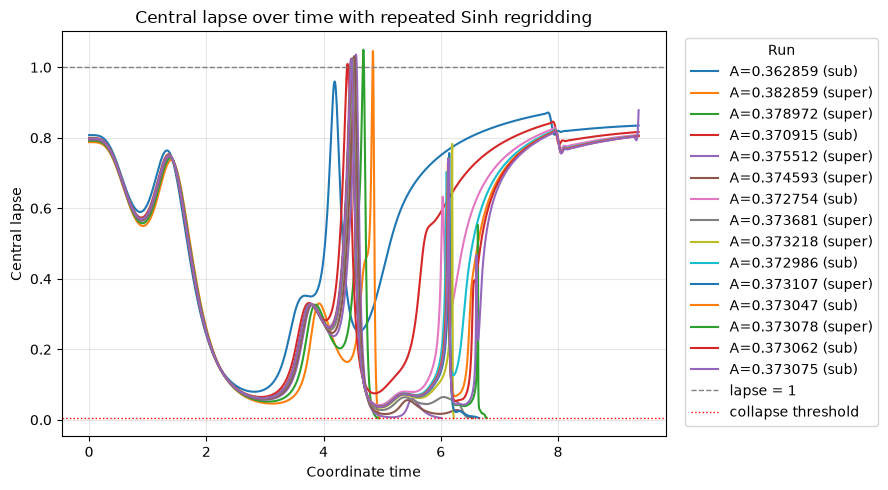

In [71]:
fig, ax = plt.subplots(figsize=(9, 5))
for run in runs_15:
    if run["outcome"] == "failed" or not run["lapse_times"]:
        continue
    ax.plot(
        run["lapse_times"], run["lapse_history"],
        label=f"A={run['A']:.6f} ({run['outcome']})",
    )
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="lapse = 1")
ax.axhline(COLLAPSE_LAPSE, color="red", linestyle=":", linewidth=1,
           label="collapse threshold")
ax.set_xlabel("Coordinate time")
ax.set_ylabel("Central lapse")
ax.set_title("Central lapse over time with repeated Sinh regridding")
ax.grid(True, alpha=0.3)
ax.legend(title="Run", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()


## 12. \(L\) versus amplitude offset

The zero of the horizontal axis is the next gradient proposal when available. It is a provisional center, not a confirmed critical amplitude. Failed records are omitted.

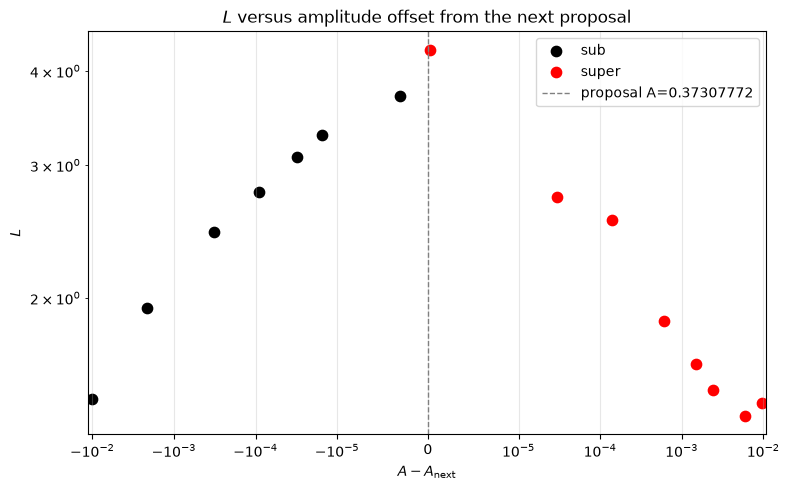

Plot center (next proposal) A = 0.37307772


In [70]:
accepted = [r for r in runs_15 if r.get("accepted", False)]
proposal_records = [
    r for r in accepted if np.isfinite(r.get("next_A_proposed", np.nan))
]
if proposal_records:
    A_star_plot = float(proposal_records[-1]["next_A_proposed"])
else:
    bracket = amplitude_bracket(runs_15)
    if bracket is None:
        raise ValueError("Need a bracket or a saved next proposal to center this plot.")
    A_star_plot = 0.5 * (bracket[0] + bracket[1])

colours = {"sub": "black", "super": "red", "unresolved": "tab:orange"}
fig, ax = plt.subplots(figsize=(8, 5))
for outcome, colour in colours.items():
    points = [r for r in runs_15 if r["outcome"] == outcome
              and np.isfinite(r["L"]) and r["L"] > 0]
    if points:
        ax.scatter(
            [r["A"] - A_star_plot for r in points],
            [r["L"] for r in points],
            color=colour, label=outcome, s=55,
        )
ax.axvline(0.0, color="gray", linestyle="--", linewidth=1,
           label=f"proposal A={A_star_plot:.8f}")
ax.set_xscale("symlog", linthresh=1e-5)
ax.set_yscale("log")
ax.set_xlabel(r"$A-A_{\mathrm{next}}$")
ax.set_ylabel(r"$L$")
ax.set_title(r"$L$ versus amplitude offset from the next proposal")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
print(f"Plot center (next proposal) A = {A_star_plot:.8f}")


In [60]:
print(amplitude_bracket(runs_15))

(0.37298583416985914, 0.3731072161924917)
